# **CS 5361/6361 Machine Learning**

**Linear Regression Exercise**


**Exercise:**

1.  Classify the MNIST dataset using linear regression by simply treating the class as a continuous variable and then rounding the results and clipping to the 0 to 9 range.  
2.  Classify the MNIST dataset using linear regression converting the class to a 10-D vector using a one-hot representation.
3.  Repeat the previous step but now add the squares of the pixel intensities as features.  

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(f'Original shapes: {x_train.shape=} {y_train.shape=} {x_test.shape=} {y_test.shape=}')
x_train = np.float32(x_train/255).reshape(x_train.shape[0],-1) # Convert every 28x28 image to a 784-element row
x_test = np.float32(x_test/255).reshape(x_test.shape[0],-1)    # Convert every 28x28 image to a 784-element row
print(f'Reshaped arrays: {x_train.shape=} {y_train.shape=} {x_test.shape=} {y_test.shape=}')

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original shapes: x_train.shape=(60000, 28, 28) y_train.shape=(60000,) x_test.shape=(10000, 28, 28) y_test.shape=(10000,)
Reshaped arrays: x_train.shape=(60000, 784) y_train.shape=(60000,) x_test.shape=(10000, 784) y_test.shape=(10000,)


Let's see some images in the MNIST dataset

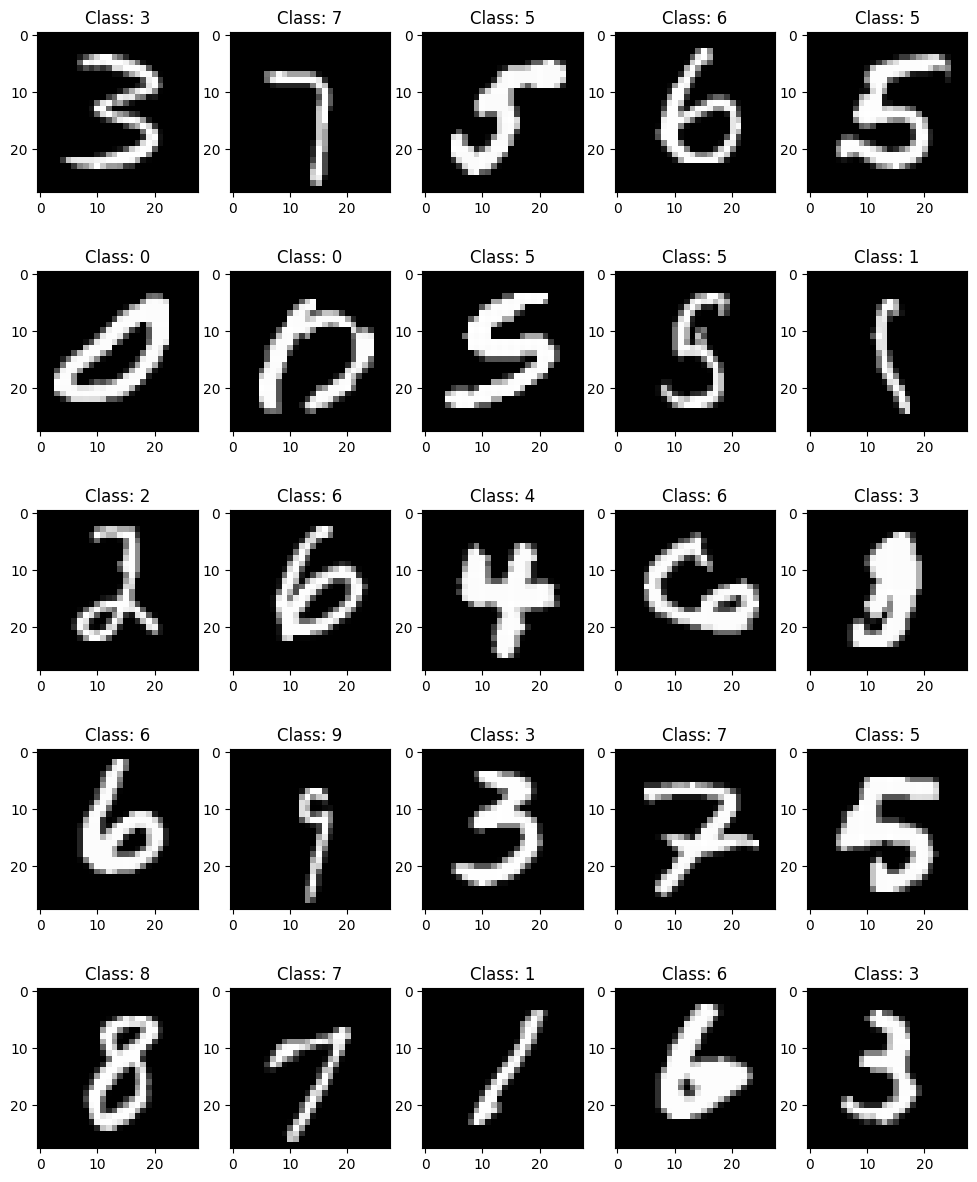

In [3]:
fig, ax = plt.subplots(nrows=5,ncols=5,figsize=(12,15))
for i in range(5):
  for j in range(5):
    d = np.random.randint(x_train.shape[0])
    ax[i,j].imshow(x_train[d].reshape(28,28),cmap='gray')
    ax[i,j].set_title(f"Class: {y_train[d]}")


## Questions (Q1–Q3)
Detailed sections and results are shown below.

# Task
Apply linear regression to the MNIST dataset using three different approaches: treating class labels as continuous, using one-hot encoded labels, and using one-hot encoded labels with added squared pixel intensity features. For each approach, train a scikit-learn LinearRegression model, make predictions, and evaluate performance using classification accuracy and a confusion matrix. Finally, summarize and compare the results of all three approaches.

## Question 1: Linear Regression with Continuous Target

### Subtask:
Implement linear regression where the class labels are treated as continuous variables. Train a scikit-learn LinearRegression model on the reshaped MNIST training data (x_train, y_train). Predict on the test data (x_test). Round the predictions to the nearest integer and clip them to the range [0, 9]. Finally, calculate and display the classification accuracy and a confusion matrix to evaluate the model's performance.


### Q1 setup

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix

print("Required libraries imported successfully.")

Required libraries imported successfully.


### Q1 training and evaluation

In [5]:
model_q1 = LinearRegression()
model_q1.fit(x_train, y_train)

y_pred_q1 = model_q1.predict(x_test)

y_pred_rounded_q1 = np.round(y_pred_q1)
y_pred_clipped_q1 = np.clip(y_pred_rounded_q1, 0, 9).astype(int)

accuracy_q1 = accuracy_score(y_test, y_pred_clipped_q1)
conf_matrix_q1 = confusion_matrix(y_test, y_pred_clipped_q1)

print(f"Accuracy for Question 1: {accuracy_q1:.4f}")
print("Confusion Matrix for Question 1:")
print(conf_matrix_q1)

Accuracy for Question 1: 0.2301
Confusion Matrix for Question 1:
[[229 322 257 104  35  23   8   2   0   0]
 [  1 228 571 221  89  18   6   1   0   0]
 [ 37 121 247 312 206  86  19   0   4   0]
 [  7  44 197 321 275 100  42  12   9   3]
 [  0   0   5  36 195 340 251 116  36   3]
 [  0   3  21 118 253 288 145  35  18  11]
 [  3   3  24  70 158 272 268 116  42   2]
 [  0   1   7  27  71 135 246 289 152 100]
 [  0   1  10  27  99 194 274 229 101  39]
 [  0   1   5   8  25  60 141 313 321 135]]


## Question 2: Linear Regression with One-Hot Encoded Target

### Subtask:
Convert the class labels (y_train, y_test) into a one-hot encoded format. Train a scikit-learn LinearRegression model using the original pixel intensities (x_train) and the one-hot encoded training labels. Predict on the test data (x_test). Convert the one-hot predictions back to class labels by selecting the index with the highest probability. Calculate and display the classification accuracy and a confusion matrix.


### Q2 training and evaluation

In [6]:
from sklearn.preprocessing import OneHotEncoder

# Reshape y_train and y_test for OneHotEncoder
y_train_reshaped = y_train.reshape(-1, 1)
y_test_reshaped = y_test.reshape(-1, 1)

# Initialize and fit OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
encoder.fit(y_train_reshaped)

# Transform y_train and y_test to one-hot encoded format
y_train_one_hot = encoder.transform(y_train_reshaped)
y_test_one_hot = encoder.transform(y_test_reshaped)

# Instantiate and train a new LinearRegression model for Question 2
model_q2 = LinearRegression()
model_q2.fit(x_train, y_train_one_hot)

# Make predictions on x_test
y_pred_one_hot = model_q2.predict(x_test)

# Convert one-hot predictions back to class labels
y_pred_q2 = np.argmax(y_pred_one_hot, axis=1)

# Calculate accuracy and confusion matrix for Question 2
accuracy_q2 = accuracy_score(y_test, y_pred_q2)
conf_matrix_q2 = confusion_matrix(y_test, y_pred_q2)

print(f"Accuracy for Question 2 (One-Hot Encoding): {accuracy_q2:.4f}")
print("Confusion Matrix for Question 2:")
print(conf_matrix_q2)

Accuracy for Question 2 (One-Hot Encoding): 0.8601
Confusion Matrix for Question 2:
[[ 943    0    2    2    2    8   13    2    7    1]
 [   0 1107    2    2    3    1    5    1   14    0]
 [  18   53  812   26   17    0   43   20   38    5]
 [   4   18   21  884    5   16    9   20   22   11]
 [   0   22    7    0  880    5   11    2   11   44]
 [  23   18    3   75   23  660   23   13   38   16]
 [  18   10   10    0   21   17  875    0    7    0]
 [   5   42   15    6   26    0    1  882    0   51]
 [  14   46   11   31   28   41   15   11  758   19]
 [  16   11    3   17   79    0    1   78    4  800]]


## Question 3: Linear Regression with One-Hot Encoded Target and Squared Features

### Subtask:
Augment the feature space by adding the squares of the pixel intensities to the original features for both `x_train` and `x_test`. Train a scikit-learn `LinearRegression` model using these augmented features and the one-hot encoded training labels (`y_train_one_hot`). Predict on the augmented test data. Convert the one-hot predictions back to class labels. Calculate and display the classification accuracy and a confusion matrix to evaluate the model's performance.

### Q3 training and evaluation

In [7]:
x_train_squared = x_train**2
x_test_squared = x_test**2

x_train_augmented = np.concatenate((x_train, x_train_squared), axis=1)
x_test_augmented = np.concatenate((x_test, x_test_squared), axis=1)

model_q3 = LinearRegression()
model_q3.fit(x_train_augmented, y_train_one_hot)

y_pred_one_hot_q3 = model_q3.predict(x_test_augmented)

y_pred_q3 = np.argmax(y_pred_one_hot_q3, axis=1)

accuracy_q3 = accuracy_score(y_test, y_pred_q3)
conf_matrix_q3 = confusion_matrix(y_test, y_pred_q3)

print(f"Accuracy for Question 3 (One-Hot Encoding with Squared Features): {accuracy_q3:.4f}")
print("Confusion Matrix for Question 3:")
print(conf_matrix_q3)

Accuracy for Question 3 (One-Hot Encoding with Squared Features): 0.8900
Confusion Matrix for Question 3:
[[ 955    0    1    3    1    5    6    1    7    1]
 [   0 1117    3    3    2    1    5    1    3    0]
 [  16   28  853   19   15    2   30   18   46    5]
 [   6   14   20  881    4   15    9   22   29   10]
 [   1   16    8    2  884    2   12    2    7   48]
 [  20    7    3   50   21  718   21   13   22   17]
 [  18    3   10    0   20   20  879    0    8    0]
 [   7   29   14    9   22    0    1  897    2   47]
 [  13   15   10   27   11   25   10    4  842   17]
 [  12   13    3   15   39    0    0   38   15  874]]


## Optional baseline: kNN classifier
This matches the instructor hint (nearest neighbors ~97% accuracy).

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3, weights="distance")
knn.fit(x_train, y_train)

y_pred_knn = knn.predict(x_test)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)

print(f"kNN Accuracy (k=3, distance): {accuracy_knn:.4f}")
print("Confusion Matrix for kNN:")
print(conf_matrix_knn)

kNN Accuracy (k=3, distance): 0.9717
Confusion Matrix for kNN:
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [   9    7  997    2    0    0    1   14    2    0]
 [   0    1    4  975    1   13    1    7    4    4]
 [   0    5    0    0  948    0    5    4    1   19]
 [   4    1    0   12    2  860    5    1    3    4]
 [   4    3    0    0    4    3  944    0    0    0]
 [   0   18    4    0    2    0    0  994    0   10]
 [   7    0    3   13    5   11    3    4  923    5]
 [   3    4    2    7    9    4    1    8    2  969]]


## Final Task

### Subtask:
Summarize the results of the three linear regression approaches, comparing their accuracy and insights gained from the confusion matrices.


## Summary:

### Data Analysis Key Findings

*   **Linear Regression with Continuous Target Labels (Approach 1)**: This approach treated class labels as continuous values and achieved a low classification accuracy of 0.2301 (23.01%). The confusion matrix indicated significant misclassifications, for example, out of 980 actual '0's, only 229 were correctly predicted as '0', while a large number were misclassified as '1' (322) and '2' (257). This highlights the limitations of using linear regression directly on continuous, rounded predictions for a multi-class classification problem without proper encoding.

*   **Linear Regression with One-Hot Encoded Target Labels (Approach 2)**: By using one-hot encoding for the target labels, the model's classification accuracy significantly improved to 0.8601 (86.01%). This demonstrates that encoding categorical targets appropriately for multi-output regression (where each output corresponds to a class probability) substantially enhances performance compared to treating them as continuous.

*   **Linear Regression with One-Hot Encoded Target Labels and Squared Features (Approach 3)**: Augmenting the feature space by adding the squares of the pixel intensities further improved the accuracy to 0.8900 (89.00%). This doubles the feature count from 784 to 1568, showing that even simple non-linear feature expansions can boost performance for linear models.

*   **kNN Baseline (Optional)**: The kNN baseline achieved 0.9717 accuracy (k=3, distance), which matches the instructor hint (~97%) and provides a strong non-linear baseline for context.

*   **Overall Comparison**: The one-hot encoding strategy (Approach 2) was vastly superior to treating labels as continuous (Approach 1). Adding squared features (Approach 3) provided an additional performance boost, making it the most accurate approach among the three tested.

### Insights or Next Steps

*   **Appropriate Target Encoding is Crucial**: For classification tasks using regression models, properly encoding categorical target variables (e.g., one-hot encoding) is critical for achieving meaningful performance, as treating them as continuous can severely limit the model's ability to learn distinct classes.
*   **Feature Engineering Enhances Linear Models**: Even simple feature engineering, such as adding polynomial terms (e.g., squared features), can significantly improve the performance of linear regression models by allowing them to model non-linear decision boundaries, making them more competitive for complex datasets like MNIST.
